# Caribu, 1: your first lit canopy

**What you will learn:** light a small crop stand with Caribu's default settings over a day, read its results (a
table per hour, a table per leaf, a table per plant), and draw the stand coloured by the light its leaves absorb.

**You need:** basic Python (running a cell, calling a function). No knowledge of light models or of metafspm is
assumed. **Run time:** about 10 seconds (the very first run on a computer also compiles the model's fast parts,
which can take a minute or two).

This is the first of six user tutorials:

| | notebook | what you do |
|---|---|---|
| 1 | `01_first_run.ipynb` | light a small crop stand over a day, read and plot the results |
| 2 | `02_change_a_parameter.ipynb` | find the parameters, change one: leaves, sun, optics, light model |
| 3 | `03_combine_parameters.ipynb` | explore leaf area and leaf angle together |
| 4 | `04_sensitivity_analysis.ipynb` | find which parameters matter most |
| 5 | `05_experimental_data.ipynb` | use a measured weather, compare with measured light, fit a parameter |
| 6 | `06_with_other_models.ipynb` | light a wheat stand grown by another model (Adel) |

Developers who want to understand how the model is written and ported will find a second series in
`../developer/`, best read after this one.

## What Caribu computes

Plants grow from the light their leaves absorb. **Caribu** computes how much light each piece of leaf receives and
absorbs in a canopy (all the leaves of a crop, seen together).

- The light that matters for photosynthesis is the **PAR** (*photosynthetically active radiation*, the wavelengths
  400 to 700 nm). It is counted in **µmol of photons per m² per second** (µmol m⁻² s⁻¹). On a sunny summer noon,
  about 2000 µmol m⁻² s⁻¹ reach the ground; under a thick overcast, a few hundred.
- Light comes from the **sun** (direct light, from one direction) and from the whole **sky** (diffuse light,
  scattered by the air and the clouds, from all directions).
- A leaf **intercepts** the light that hits it. It **absorbs** most of it (about 85 % in the PAR), and **reflects**
  and **transmits** (lets through) the rest. Leaves high in the canopy **shade** those below.
- The light reflected or transmitted by a leaf can hit other leaves: this is **scattering**. Caribu can ignore it
  (the *direct* model, fast) or compute it (the *nested radiosity* model, more exact).
- A field is far larger than the plants we describe. Caribu repeats the small stand on every side, like tiles, so
  that the plants at its edges are shaded as in the middle of a field: an **infinite canopy**.

Caribu describes the leaves as small triangles, each lit separately.

*Reference:* Chelle M., Andrieu B., Bouatouch K. (1998). Nested radiosity for plant canopies. *The Visual Computer*
14, 109–125.

*A word on metafspm:* this package is written with metafspm, a framework in which plant models are built as
**components** that can be combined (a light model, a plant growth model, a soil model...). You do not need to know
it to use Caribu; the last section of this tutorial says a word about how it works.

## 1. Light a stand

`simulate` lights a small stand of simple plants hour by hour over a day. With no argument, it uses Caribu's
**default settings** and a default stand:

- 3 rows 15 cm apart, 8 plants per row 5 cm apart;
- each plant is a stem of 40 cm and 4 leaves: flat strips 20 cm long and 1.5 cm wide, inclined 30° above the
  horizontal, on alternate sides of the stem;
- the default day is 21 June at Paris (latitude 48.85°N), with the PAR of a clear day;
- the default sky is **overcast** (only diffuse light, no sun), and the model is the **direct** one (no scattering).

The hours are in universal time (UT); at Paris the sun is highest at about 11:50 UT.

In [1]:
import matplotlib.pyplot as plt

from openalea.caribu.simulation import simulate

result = simulate()

A useful number to describe a canopy is its **leaf area index** (LAI): the area of leaves (one face) per area of
ground. Here:

In [2]:
plants = result.plants()
LAI = plants["leaf_area"].sum() / result.ground_area
print(f"{len(plants)} plants on {result.ground_area:.2f} m² of ground, LAI = {LAI:.2f}")

24 plants on 0.18 m² of ground, LAI = 3.20


## 2. The summary: one row per hour

`result.summary` is a table (a pandas DataFrame) with one row per hour:

| column | meaning | unit |
|---|---|---|
| `hour` | hour of the day (universal time) | h |
| `PARi` | PAR above the canopy, on a horizontal surface | µmol m⁻² s⁻¹ |
| `PAR_absorbed` | PAR absorbed by the leaves and stems, per m² of ground | µmol m⁻² s⁻¹ |
| `absorbed_fraction` | share of the PAR above the canopy that the canopy absorbs | – |
| `soil_fraction` | share that reaches the soil without touching a leaf (direct model only) | – |

In [3]:
result.summary.round(3)

,hour,PARi,PAR_absorbed,absorbed_fraction,soil_fraction
0,0.0,0.000,0.000,0.658,0.228
1,1.0,0.000,0.000,0.658,0.228
2,2.0,0.000,0.000,0.658,0.228
3,3.0,0.000,0.000,0.658,0.228
4,4.0,0.000,0.000,0.658,0.228
5,5.0,139.258,91.625,0.658,0.228
6,6.0,432.279,284.419,0.658,0.228
7,7.0,735.652,484.024,0.658,0.228
8,8.0,1028.707,676.840,0.658,0.228
9,9.0,1291.480,849.731,0.658,0.228


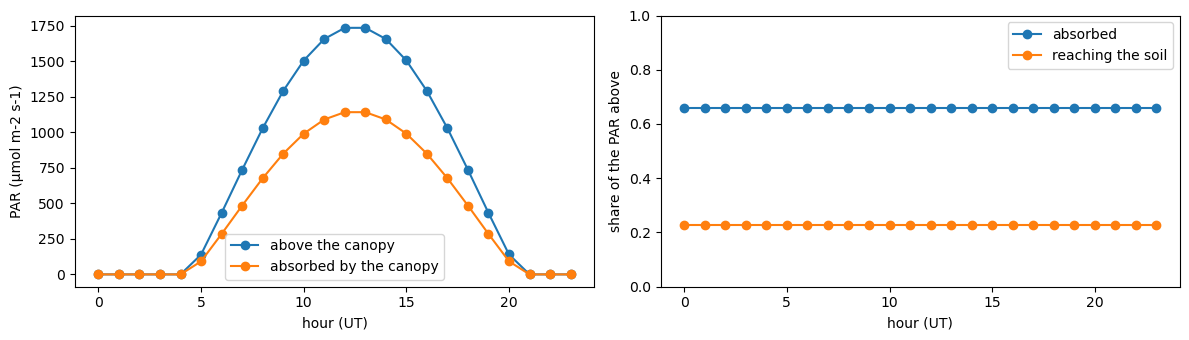

In [4]:
summary = result.summary
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(summary["hour"], summary["PARi"], marker="o", label="above the canopy")
axes[0].plot(summary["hour"], summary["PAR_absorbed"], marker="o", label="absorbed by the canopy")
axes[0].set_ylabel("PAR (µmol m-2 s-1)"); axes[0].legend()
axes[1].plot(summary["hour"], summary["absorbed_fraction"], marker="o", label="absorbed")
axes[1].plot(summary["hour"], summary["soil_fraction"], marker="o", label="reaching the soil")
axes[1].set_ylabel("share of the PAR above"); axes[1].set_ylim(0, 1); axes[1].legend()
for ax in axes:
    ax.set_xlabel("hour (UT)")
plt.tight_layout()

**Reading the curves.**

- The canopy absorbs the same share of the light at every hour: 66 %. Under the default overcast sky, the light
  comes from the whole sky with the same distribution at every hour, so only its amount changes. With the sun
  (tutorial 2), the share changes with the sun's position.
- 23 % reaches the soil through the gaps between the leaves.
- The rest, about 11 %, is intercepted but not absorbed: the leaves reflect or transmit it. The direct model
  ignores what becomes of it.

Over the day, the PAR above the canopy and the PAR absorbed add up to (1 µmol m⁻² s⁻¹ for an hour is 0.0036 mol
m⁻²):

In [5]:
incident = summary["PARi"].sum() * 3600 / 1e6
absorbed = summary["PAR_absorbed"].sum() * 3600 / 1e6
print(f"over the day: {incident:.1f} mol m-2 above the canopy, {absorbed:.1f} mol m-2 absorbed "
      f"({absorbed / incident:.0%})")

over the day: 61.4 mol m-2 above the canopy, 40.4 mol m-2 absorbed (66%)


## 3. Draw the stand

`result.draw()` shows the stand in 3D, each leaf coloured by **Erel**: the PAR it absorbs per unit of its area,
relative to the PAR above the canopy. An Erel of 0.6 means that the leaf absorbs, per m² of leaf, 60 % of the PAR
falling on 1 m² of open ground.

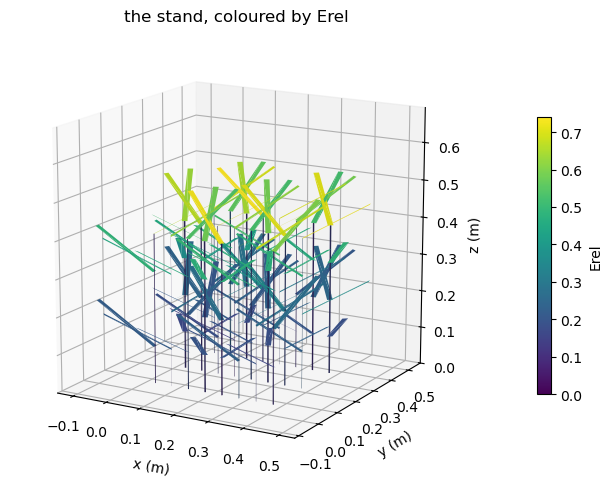

In [6]:
result.draw()
plt.title("the stand, coloured by Erel");

## 4. Light down the canopy

`result.elements()` lists every leaf and stem, one row each:

- `plant` (its number), `kind` (`leaf` or `stem`), `leaf_rank` (1 for the lowest leaf);
- `height` (m, its middle), `area` (m²);
- `Erel`; `PARa`, the PAR it absorbs per m² at the last hour (here 23 h, at night: 0);
- `absorbed`, the PAR it absorbed over the whole run (µmol).

The mean Erel of the leaves of each rank shows how the light falls down the canopy:

,height,Erel
leaf_rank,,
1,0.15,0.197
2,0.25,0.269
3,0.35,0.459
4,0.45,0.644


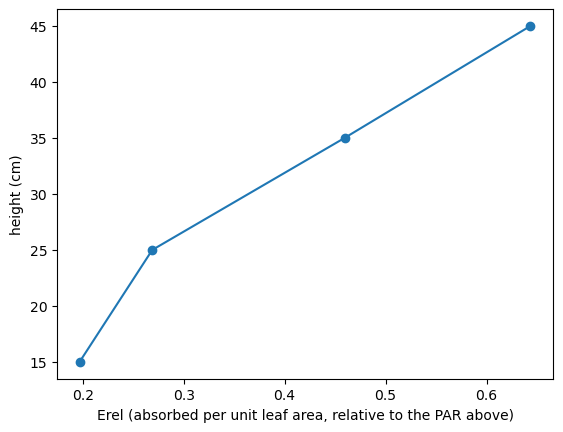

In [7]:
elements = result.elements()
leaves = elements[elements["kind"] == "leaf"]
by_rank = leaves.groupby("leaf_rank")[["height", "Erel"]].mean()
plt.plot(by_rank["Erel"], by_rank["height"] * 100, "o-")
plt.xlabel("Erel (absorbed per unit leaf area, relative to the PAR above)"); plt.ylabel("height (cm)")
by_rank.round(3)

The top leaves absorb more than three times as much per unit area as the lowest ones: they are lit by the open
sky, the lower ones through the gaps left by those above.

## 5. Per plant

`result.plants()` gives each plant's leaf area (m²) and the PAR it absorbed over the run (mol). The plants are
identical, but each is turned by a different angle: their leaves face different directions and shade each other
differently.

In [8]:
plants = result.plants()
print(f"PAR absorbed per plant over the day: from {plants['absorbed'].min():.3f} to {plants['absorbed'].max():.3f} "
      f"mol (mean {plants['absorbed'].mean():.3f})")
plants.head()

PAR absorbed per plant over the day: from 0.507 to 0.708 mol (mean 0.606)


,leaf_area,absorbed
plant,,
0,0.024000,0.631696
1,0.024000,0.594538
2,0.023999,0.563277
3,0.024001,0.563859
4,0.023999,0.640731


## Saving a run

With `outputs=`, `simulate` also writes the run in a folder, to keep it, compare it with others later, or open it in
another program:

- `run.json`: how the run went (finished, or the error that stopped it), when, and how long it took;
- `scenario.json`: everything the run was made with (the plants, the light's settings, the PAR above the stand), to
  run it again;
- `summaries/hand_declared/summary.csv`: the summary above;
- `summaries/Plant/SimplePlantModel/summaries.csv`: the light each plant absorbs, hour by hour;
- `frames.fspm.zip`: the whole stand every hour, in the encoding3d format that ParaView (with encoding3d's reader) and
  other plant modelling platforms open: colour the leaves by `PARa` to watch the light move over the day. The frames
  are written in a folder, `frames/`, while the run goes; at the end they are packed into this one file, the file is
  checked, and the folder is removed.

In [9]:
import json
import os

import pandas as pd

saved = simulate(outputs="outputs/first_run")
print(sorted(os.listdir("outputs/first_run")))
with open("outputs/first_run/run.json") as file:
    run = json.load(file)
print(run["status"], "in", round(run["wall_time"], 1), "s")
pd.read_csv("outputs/first_run/summaries/hand_declared/summary.csv").iloc[10:14]

['Plant', 'frames.fspm.zip', 'run.json', 'scenario.json', 'summary.csv']
finished in 1.9 s


,hour,PARi,PAR_absorbed,absorbed_fraction,soil_fraction
10,10.0,1506.066011,990.919006,0.657952,0.227934
11,11.0,1657.847058,1090.783636,0.657952,0.227934
12,12.0,1736.481893,1142.521576,0.657952,0.227934
13,13.0,1736.613148,1142.607936,0.657952,0.227934


## Try it yourself

1. Light only the hours from 6 to 18 h: `simulate(hours=13, start_hour=6)`. Is the daily absorbed PAR different?
   Why so little?
2. Which leaf of which plant absorbs the most light over the day? (Use `elements` and `idxmax`.)
3. Draw the stand coloured by `PARa` after `simulate(hours=1, start_hour=12)`.

**Next:** `02_change_a_parameter.ipynb`, to change the plants, the sky and the model.

## Behind `simulate`: how the model is meant to be used

`simulate` is a convenience for these tutorials, not the model itself. The model is the component `CaribuLight` (in
`openalea.caribu.component`). In metafspm a component is not run on its own. Its intended use has three layers:

1. **The components.** `CaribuLight` holds the light model: it lights the triangles of the plants' elements and
   writes each element's absorbed light. It does not create plants. The plants come from another component that
   describes their shape: here `SimplePlant`, a deliberately simple plant written for these tutorials (in
   `openalea.caribu.simulation`); in real use, a plant architecture model such as Adel's wheat (tutorial 6).
2. **A plant model** (a metafspm `CompositeModel`) gathers the components of a plant: its architecture, its
   photosynthesis, its growth... The plant model **couples** them, connecting what one computes to what another
   needs. For example, the PAR a leaf absorbs (`PARa`) is the input of a photosynthesis model.
3. **A scene** (a metafspm `Scene`) plants the plants at their positions and holds the **environment models**, those
   that act on all the plants together: the light is one (`CaribuLightModel`, wrapping `CaribuLight`), a soil
   another. The scene advances them all, step by step, and gives them the weather (here the PAR above the canopy,
   `PARi`).

`simulate` builds the simplest case: a stand of `SimplePlant`s in a scene with `CaribuLightModel`, the PAR above
the canopy given as a time series (metafspm's forcings), its results recorded by metafspm's `SceneRecorder` (the
summary, and the files of `outputs=`). To light plants grown by other models, or
to couple the absorbed light to a photosynthesis model, you write the plant model and the scene yourself. metafspm's
beginner page, [metafspm in five minutes](https://github.com/openalea/metafspm/blob/release2026/docs/five_minutes.md), explains components, plant models and scenes in
plain words. The developer tutorial `../developer/01_caribu_in_metafspm.ipynb` shows how: the component's
declarations and steps, the light models underneath it, a scene of Adel's wheat lit by Caribu. Its overview,
`../developer/00_overview.ipynb`, describes the package.